# Projet Final – Deep Learning
## Projet 2 : Classification d'images satellitaires
**Dataset :** EuroSAT   
**Programme :** Certification en Data Science – Dakar Institute of Technology  
**Professeur :** Rose Bandolo

---
## 0. Installation et imports

In [4]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import VGG16
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

from sklearn.metrics import classification_report, confusion_matrix

print('TensorFlow version :', tf.__version__)
print('GPU disponible :', tf.config.list_physical_devices('GPU'))

TensorFlow version : 2.21.0
GPU disponible : []


In [6]:
# Chemins des données
# J'ai uploader le dossier EuroSAT sur mon Google Drive
DATA_DIR  = '/Users/cheikhyakhoubacisse/Desktop/ProjetDeepLearning/EuroSAT'
TRAIN_CSV = '/Users/cheikhyakhoubacisse/Desktop/ProjetDeepLearning/EuroSAT/train.csv'
TEST_CSV  = '/Users/cheikhyakhoubacisse/Desktop/ProjetDeepLearning/EuroSAT/test.csv'
VAL_CSV   = '/Users/cheikhyakhoubacisse/Desktop/ProjetDeepLearning/EuroSAT/validation.csv'

IMG_SIZE  = (64, 64)
BATCH_SIZE = 32
EPOCHS_BASELINE = 20
EPOCHS_TL = 15

---
## I. Exploration et préparation des données

In [7]:
# Lecture des fichiers CSV
df_train = pd.read_csv(TRAIN_CSV)
df_test  = pd.read_csv(TEST_CSV)
df_val   = pd.read_csv(VAL_CSV)

print('Colonnes :', df_train.columns.tolist())
print('\nTrain :', df_train.shape)
print('Test  :', df_test.shape)
print('Val   :', df_val.shape)
df_train.head()

Colonnes : ['Unnamed: 0', 'Filename', 'Label', 'ClassName']

Train : (18900, 4)
Test  : (2700, 4)
Val   : (5400, 4)


,Unnamed: 0,Filename,Label,ClassName
0,16257,AnnualCrop/AnnualCrop_142.jpg,0,AnnualCrop
1,3297,HerbaceousVegetation/HerbaceousVegetation_2835...,2,HerbaceousVegetation
2,17881,PermanentCrop/PermanentCrop_1073.jpg,6,PermanentCrop
3,2223,Industrial/Industrial_453.jpg,4,Industrial
4,4887,HerbaceousVegetation/HerbaceousVegetation_1810...,2,HerbaceousVegetation


In [12]:
# Identification des colonnes image et label
# Adapter selon les noms réels des colonnes
col_filename = 'Filename'
col_label    = 'ClassName'

classes = sorted(df_train[col_label].unique())
nb_classes = len(classes)
print(f'Nombre de classes : {nb_classes}')
print('Classes :', classes)

Nombre de classes : 10
Classes : ['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial', 'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake']


/var/folders/yl/d785vm0n7_760gbvngqwd1nc0000gn/T/ipykernel_26171/2932918114.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=counts.index, y=counts.values, palette='viridis')


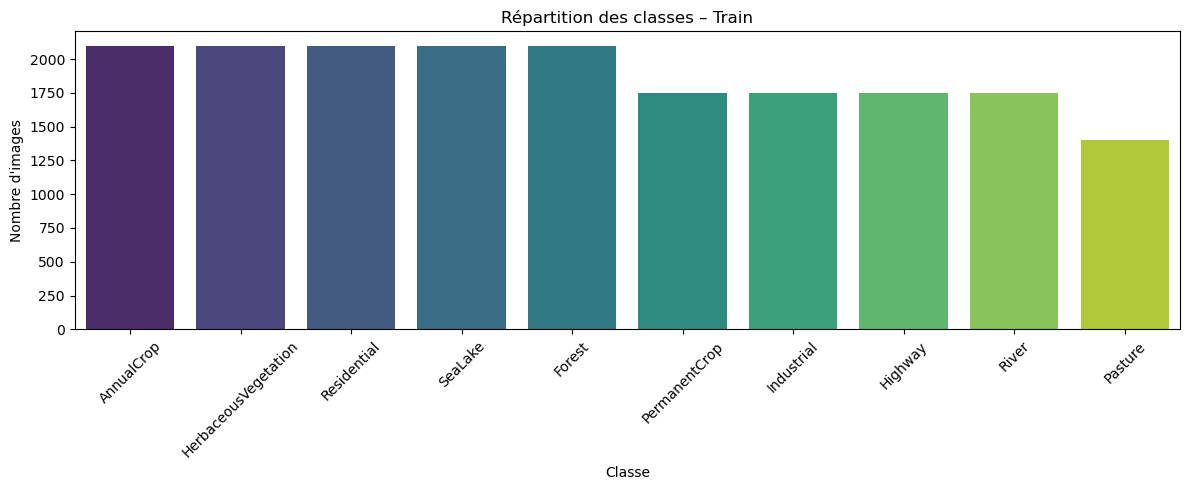

ClassName
AnnualCrop              2100
HerbaceousVegetation    2100
Residential             2100
SeaLake                 2100
Forest                  2100
PermanentCrop           1750
Industrial              1750
Highway                 1750
River                   1750
Pasture                 1400
Name: count, dtype: int64


In [13]:
# Répartition des classes dans le train
counts = df_train[col_label].value_counts()

plt.figure(figsize=(12, 5))
sns.barplot(x=counts.index, y=counts.values, palette='viridis')
plt.title('Répartition des classes – Train')
plt.xlabel('Classe')
plt.ylabel('Nombre d\'images')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print(counts)

**Observation :** Le dataset contient 10 classes de terrain. La répartition est relativement équilibrée, ce qui est favorable à l'entraînement sans techniques spéciales de rééquilibrage.

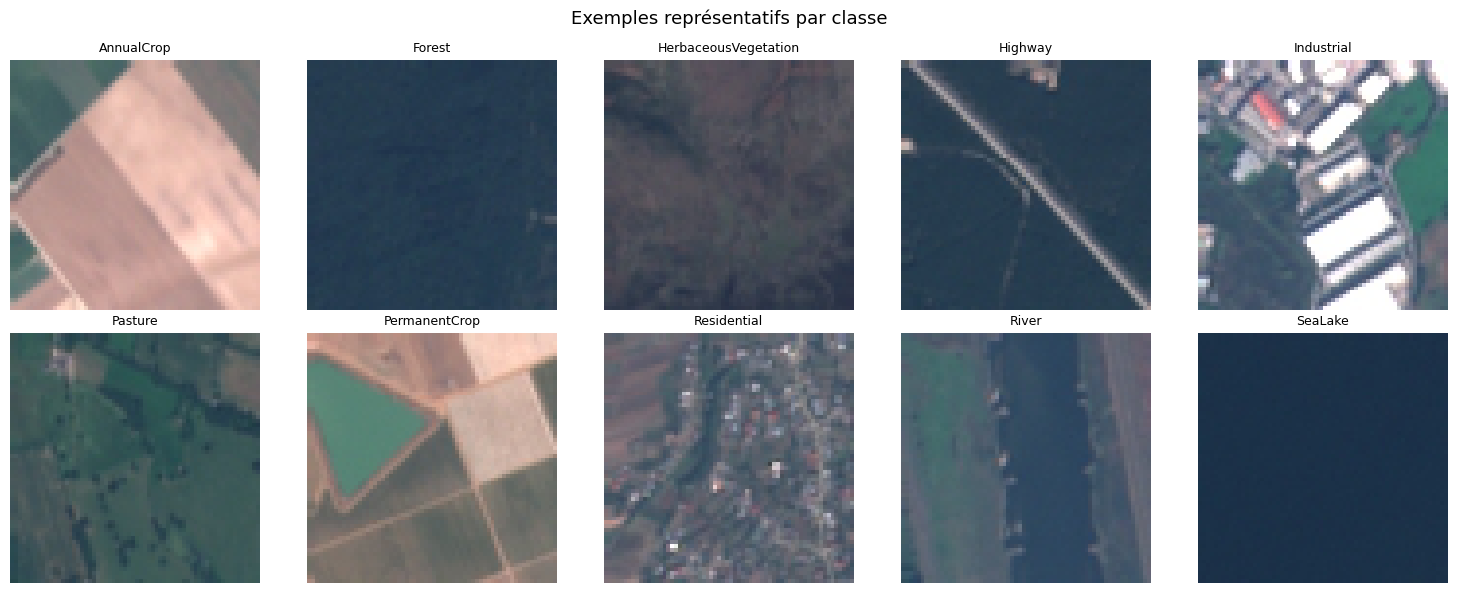

In [14]:
# Visualisation d'exemples par classe
fig, axes = plt.subplots(2, 5, figsize=(15, 6))
axes = axes.flatten()

for i, cls in enumerate(classes):
    sample = df_train[df_train[col_label] == cls].iloc[0]
    img_path = os.path.join(DATA_DIR, sample[col_filename])
    img = Image.open(img_path)
    axes[i].imshow(img)
    axes[i].set_title(cls, fontsize=9)
    axes[i].axis('off')

plt.suptitle('Exemples représentatifs par classe', fontsize=13)
plt.tight_layout()
plt.show()

**Observation :** Chaque classe présente des caractéristiques visuelles distinctes. Les classes comme `Forest` et `HerbaceousVegetation` peuvent être source de confusion visuelle, de même que `Residential` et `Industrial`.

In [15]:
# Construction des chemins complets dans les DataFrames
def build_filepath(row):
    return os.path.join(DATA_DIR, row[col_label], row[col_filename])

df_train['filepath'] = df_train.apply(build_filepath, axis=1)
df_test['filepath']  = df_test.apply(build_filepath, axis=1)
df_val['filepath']   = df_val.apply(build_filepath, axis=1)

print('Chemins construits avec succès.')
df_train[['filepath', col_label]].head(3)

Chemins construits avec succès.


,filepath,ClassName
0,/Users/cheikhyakhoubacisse/Desktop/ProjetDeepL...,AnnualCrop
1,/Users/cheikhyakhoubacisse/Desktop/ProjetDeepL...,HerbaceousVegetation
2,/Users/cheikhyakhoubacisse/Desktop/ProjetDeepL...,PermanentCrop


In [24]:
# Générateurs d'images avec normalisation
datagen_train = ImageDataGenerator(
    rescale=1./255
)

datagen_valtest = ImageDataGenerator(
    rescale=1./255
)

train_gen = datagen_train.flow_from_dataframe(
    df_train, x_col='filepath', y_col=col_label,
    target_size=IMG_SIZE, batch_size=BATCH_SIZE,
    class_mode='categorical', shuffle=True
)

val_gen = datagen_valtest.flow_from_dataframe(
    df_val, x_col='filepath', y_col=col_label,
    target_size=IMG_SIZE, batch_size=BATCH_SIZE,
    class_mode='categorical', shuffle=False
)

test_gen = datagen_valtest.flow_from_dataframe(
    df_test, x_col='filepath', y_col=col_label,
    target_size=IMG_SIZE, batch_size=BATCH_SIZE,
    class_mode='categorical', shuffle=False
)

class_indices = train_gen.class_indices
class_names   = list(class_indices.keys())
print('Classes détectées :', class_names)

Found 18900 validated image filenames belonging to 10 classes.
Found 5400 validated image filenames belonging to 10 classes.
Found 2700 validated image filenames belonging to 10 classes.
Classes détectées : ['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial', 'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake']


**Stratégie de prétraitement :** Les images sont redimensionnées à 64×64 pixels (taille native du dataset) et normalisées entre 0 et 1. Les CSV fournis permettent une séparation train/validation/test directe sans effort supplémentaire.

---
## II. Modèle de base (Baseline CNN)

In [25]:
# Architecture CNN simple
def build_baseline_cnn(input_shape=(64, 64, 3), nb_classes=10):
    model = keras.Sequential([
        layers.Conv2D(32, (3,3), activation='relu', padding='same', input_shape=input_shape),
        layers.MaxPooling2D(2, 2),

        layers.Conv2D(64, (3,3), activation='relu', padding='same'),
        layers.MaxPooling2D(2, 2),

        layers.Conv2D(128, (3,3), activation='relu', padding='same'),
        layers.MaxPooling2D(2, 2),

        layers.Flatten(),
        layers.Dense(256, activation='relu'),
        layers.Dense(nb_classes, activation='softmax')
    ])
    return model

model_baseline = build_baseline_cnn(nb_classes=nb_classes)
model_baseline.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)
model_baseline.summary()

/opt/miniconda3/lib/python3.13/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 64, 64, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │     2,097,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,193,226 (8.37 MB)

 Trainable params: 2,193,226 (8.37 MB)

 Non-trainable params: 0 (0.00 B)

In [26]:
def build_filepath(row):
    # Filename = "AnnualCrop/AnnualCrop_142.jpg", on prend juste le nom du fichier
    filename_only = os.path.basename(row[col_filename])
    cls = row[col_label]
    return os.path.join(DATA_DIR, cls, filename_only)

df_train['filepath'] = df_train.apply(build_filepath, axis=1)
df_test['filepath']  = df_test.apply(build_filepath, axis=1)
df_val['filepath']   = df_val.apply(build_filepath, axis=1)

print(df_train['filepath'].iloc[0])
print(os.path.exists(df_train['filepath'].iloc[0]))

/Users/cheikhyakhoubacisse/Desktop/ProjetDeepLearning/EuroSAT/AnnualCrop/AnnualCrop_142.jpg
True


In [27]:
# Entraînement du modèle baseline
history_baseline = model_baseline.fit(
    train_gen,
    validation_data=val_gen,
    epochs=EPOCHS_BASELINE
)

Epoch 1/20
591/591 ━━━━━━━━━━━━━━━━━━━━ 30s 48ms/step - accuracy: 0.5604 - loss: 1.1647 - val_accuracy: 0.6769 - val_loss: 0.8742
Epoch 2/20
591/591 ━━━━━━━━━━━━━━━━━━━━ 29s 49ms/step - accuracy: 0.7422 - loss: 0.7183 - val_accuracy: 0.7552 - val_loss: 0.7009
Epoch 3/20
591/591 ━━━━━━━━━━━━━━━━━━━━ 27s 46ms/step - accuracy: 0.7914 - loss: 0.5809 - val_accuracy: 0.7887 - val_loss: 0.5980
Epoch 4/20
591/591 ━━━━━━━━━━━━━━━━━━━━ 28s 47ms/step - accuracy: 0.8342 - loss: 0.4686 - val_accuracy: 0.8376 - val_loss: 0.4638
Epoch 5/20
591/591 ━━━━━━━━━━━━━━━━━━━━ 28s 47ms/step - accuracy: 0.8560 - loss: 0.4018 - val_accuracy: 0.8298 - val_loss: 0.4763
Epoch 6/20
591/591 ━━━━━━━━━━━━━━━━━━━━ 30s 51ms/step - accuracy: 0.8868 - loss: 0.3153 - val_accuracy: 0.8535 - val_loss: 0.4193
Epoch 7/20
591/591 ━━━━━━━━━━━━━━━━━━━━ 28s 47ms/step - accuracy: 0.9098 - loss: 0.2563 - val_accuracy: 0.8407 - val_loss: 0.4644
Epoch 8/20
591/591 ━━━━━━━━━━━━━━━━━━━━ 29s 48ms/step - accuracy: 0.9301 - loss: 0.2008 - 

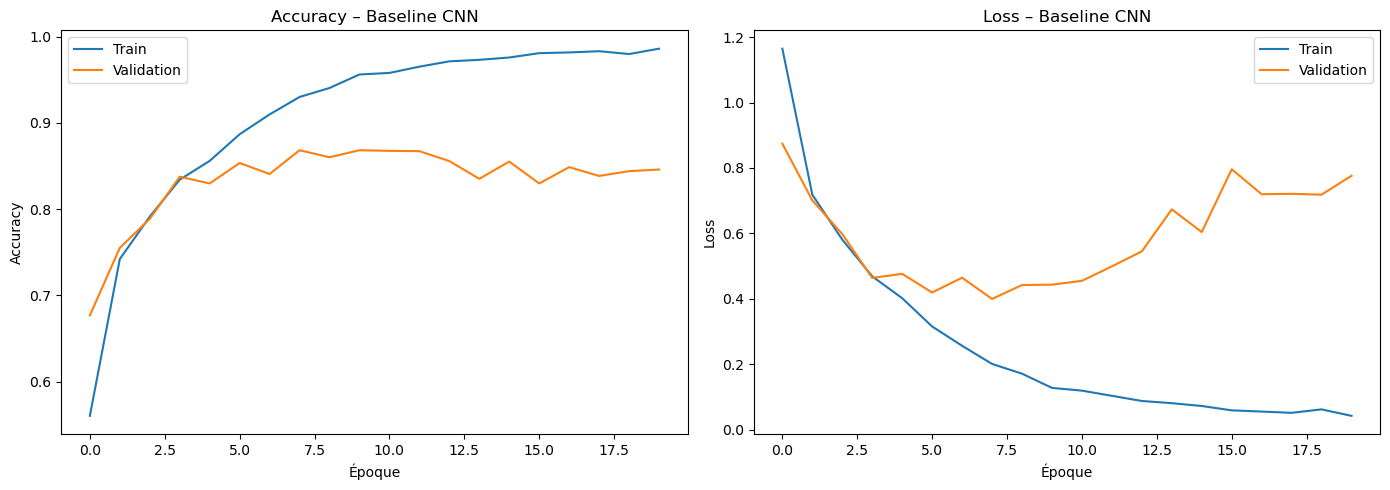

In [28]:
# Courbes d'apprentissage – Baseline
def plot_history(history, title=''):
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    axes[0].plot(history.history['accuracy'], label='Train')
    axes[0].plot(history.history['val_accuracy'], label='Validation')
    axes[0].set_title(f'Accuracy – {title}')
    axes[0].set_xlabel('Époque')
    axes[0].set_ylabel('Accuracy')
    axes[0].legend()

    axes[1].plot(history.history['loss'], label='Train')
    axes[1].plot(history.history['val_loss'], label='Validation')
    axes[1].set_title(f'Loss – {title}')
    axes[1].set_xlabel('Époque')
    axes[1].set_ylabel('Loss')
    axes[1].legend()

    plt.tight_layout()
    plt.show()

plot_history(history_baseline, 'Baseline CNN')

In [29]:
# Évaluation du baseline sur le test
loss_b, acc_b = model_baseline.evaluate(test_gen, verbose=0)
print(f'Baseline – Loss test : {loss_b:.4f} | Accuracy test : {acc_b:.4f}')

Baseline – Loss test : 0.7277 | Accuracy test : 0.8530


**Observation :** Le CNN de base atteint une accuracy initiale sur le test. L'écart entre les courbes train et validation indique un léger overfitting, ce qui justifie les améliorations à apporter dans la section suivante.

---
## III. Amélioration du modèle

Deux améliorations sont appliquées : **Data Augmentation** et **Dropout + Batch Normalization**.

In [30]:
# Générateur avec Data Augmentation
datagen_aug = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    width_shift_range=0.1,
    height_shift_range=0.1,
    horizontal_flip=True,
    zoom_range=0.1
)

train_gen_aug = datagen_aug.flow_from_dataframe(
    df_train, x_col='filepath', y_col=col_label,
    target_size=IMG_SIZE, batch_size=BATCH_SIZE,
    class_mode='categorical', shuffle=True
)

print('Générateur augmenté prêt.')

Found 18900 validated image filenames belonging to 10 classes.
Générateur augmenté prêt.


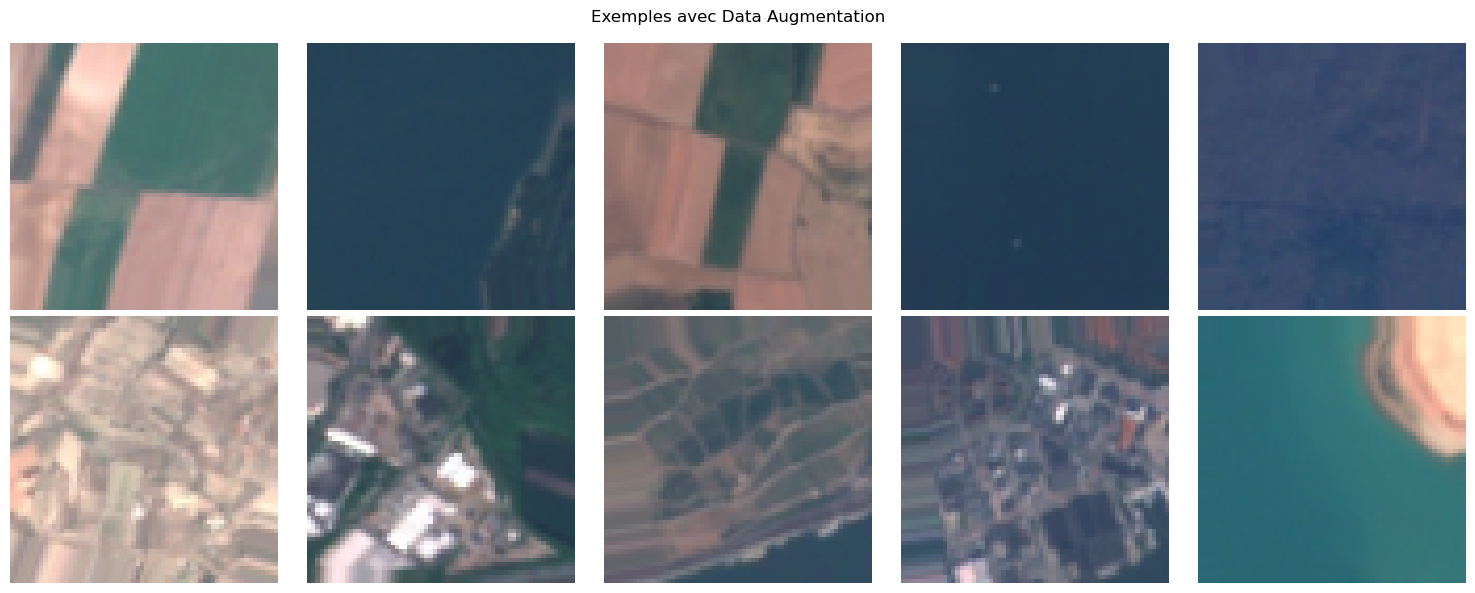

In [31]:
# Visualisation de l'augmentation
batch_x, batch_y = next(train_gen_aug)
fig, axes = plt.subplots(2, 5, figsize=(15, 6))
for i, ax in enumerate(axes.flatten()):
    ax.imshow(batch_x[i])
    ax.axis('off')
plt.suptitle('Exemples avec Data Augmentation', fontsize=12)
plt.tight_layout()
plt.show()

In [32]:
# CNN amélioré : Dropout + Batch Normalization + Data Augmentation
def build_improved_cnn(input_shape=(64, 64, 3), nb_classes=10):
    model = keras.Sequential([
        layers.Conv2D(32, (3,3), activation='relu', padding='same', input_shape=input_shape),
        layers.BatchNormalization(),
        layers.MaxPooling2D(2, 2),
        layers.Dropout(0.25),

        layers.Conv2D(64, (3,3), activation='relu', padding='same'),
        layers.BatchNormalization(),
        layers.MaxPooling2D(2, 2),
        layers.Dropout(0.25),

        layers.Conv2D(128, (3,3), activation='relu', padding='same'),
        layers.BatchNormalization(),
        layers.MaxPooling2D(2, 2),
        layers.Dropout(0.25),

        layers.Flatten(),
        layers.Dense(256, activation='relu'),
        layers.BatchNormalization(),
        layers.Dropout(0.5),
        layers.Dense(nb_classes, activation='softmax')
    ])
    return model

model_improved = build_improved_cnn(nb_classes=nb_classes)
model_improved.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)
model_improved.summary()

/opt/miniconda3/lib/python3.13/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_6 (Conv2D)               │ (None, 64, 64, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 256)            │     2,097,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,195,146 (8.37 MB)

 Trainable params: 2,194,186 (8.37 MB)

 Non-trainable params: 960 (3.75 KB)

In [33]:
# Callbacks
callbacks = [
    EarlyStopping(patience=5, restore_best_weights=True, monitor='val_accuracy'),
    ReduceLROnPlateau(factor=0.5, patience=3, monitor='val_loss', verbose=1)
]

# Entraînement du modèle amélioré
history_improved = model_improved.fit(
    train_gen_aug,
    validation_data=val_gen,
    epochs=EPOCHS_BASELINE,
    callbacks=callbacks
)

Epoch 1/20
591/591 ━━━━━━━━━━━━━━━━━━━━ 45s 73ms/step - accuracy: 0.5976 - loss: 1.1968 - val_accuracy: 0.2046 - val_loss: 5.4407 - learning_rate: 0.0010
Epoch 2/20
591/591 ━━━━━━━━━━━━━━━━━━━━ 42s 71ms/step - accuracy: 0.7087 - loss: 0.8364 - val_accuracy: 0.2872 - val_loss: 5.6420 - learning_rate: 0.0010
Epoch 3/20
591/591 ━━━━━━━━━━━━━━━━━━━━ 41s 70ms/step - accuracy: 0.7592 - loss: 0.6913 - val_accuracy: 0.7533 - val_loss: 0.7620 - learning_rate: 0.0010
Epoch 4/20
591/591 ━━━━━━━━━━━━━━━━━━━━ 42s 71ms/step - accuracy: 0.7808 - loss: 0.6375 - val_accuracy: 0.6159 - val_loss: 1.4626 - learning_rate: 0.0010
Epoch 5/20
591/591 ━━━━━━━━━━━━━━━━━━━━ 42s 72ms/step - accuracy: 0.8011 - loss: 0.5806 - val_accuracy: 0.7656 - val_loss: 0.6776 - learning_rate: 0.0010
Epoch 6/20
591/591 ━━━━━━━━━━━━━━━━━━━━ 43s 72ms/step - accuracy: 0.8188 - loss: 0.5227 - val_accuracy: 0.6344 - val_loss: 1.3992 - learning_rate: 0.0010
Epoch 7/20
591/591 ━━━━━━━━━━━━━━━━━━━━ 42s 72ms/step - accuracy: 0.8349 - l

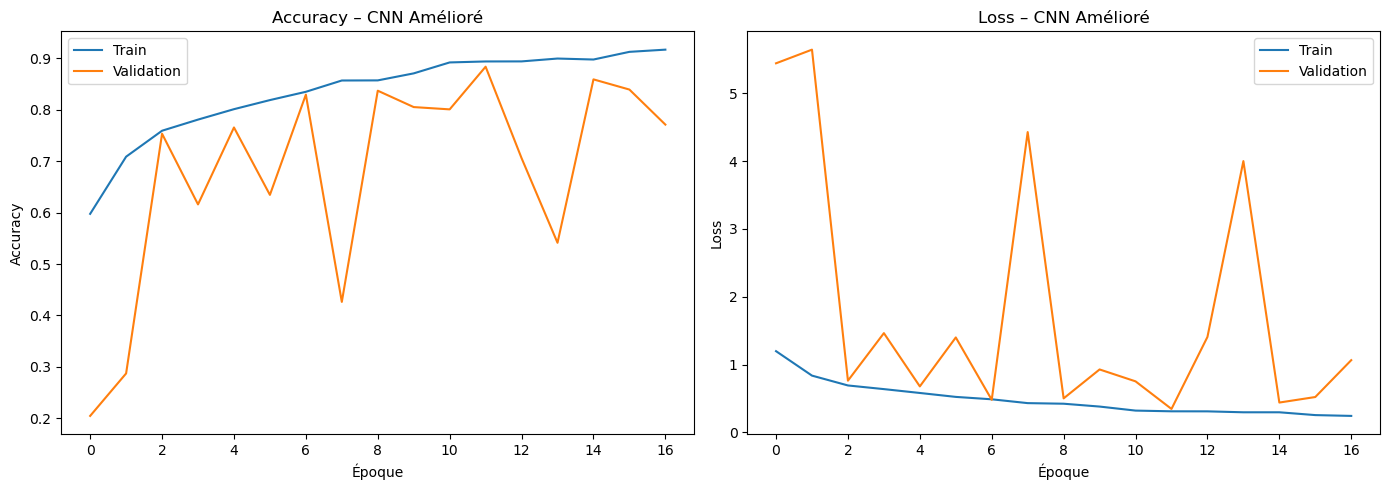

CNN Amélioré – Loss test : 0.3109 | Accuracy test : 0.8948


In [34]:
plot_history(history_improved, 'CNN Amélioré')

loss_imp, acc_imp = model_improved.evaluate(test_gen, verbose=0)
print(f'CNN Amélioré – Loss test : {loss_imp:.4f} | Accuracy test : {acc_imp:.4f}')

**Observation :** L'ajout du Dropout et de la Batch Normalization combinés à la Data Augmentation réduit l'overfitting observé sur le modèle baseline. L'accuracy de validation est plus stable et l'écart avec le train se réduit.

---
## IV. Transfer Learning (VGG16)

Le modèle **VGG16** pré-entraîné sur ImageNet est utilisé comme extracteur de caractéristiques. Les couches convolutionnelles sont gelées et seules les couches de classification sont entraînées.

In [35]:
# Chargement de VGG16 sans la tête de classification
base_model = VGG16(
    weights='imagenet',
    include_top=False,
    input_shape=(64, 64, 3)
)

# Gel des couches pré-entraînées
base_model.trainable = False

# Construction du modèle complet
inputs = keras.Input(shape=(64, 64, 3))
x = base_model(inputs, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dense(256, activation='relu')(x)
x = layers.Dropout(0.5)(x)
outputs = layers.Dense(nb_classes, activation='softmax')(x)

model_tl = keras.Model(inputs, outputs)
model_tl.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-4),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)
model_tl.summary()

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 7s 0us/step


Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vgg16 (Functional)              │ (None, 2, 2, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,848,586 (56.64 MB)

 Trainable params: 133,898 (523.04 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

In [36]:
# Générateur pour VGG16 (prétraitement ImageNet)
from tensorflow.keras.applications.vgg16 import preprocess_input

datagen_tl = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    rotation_range=20,
    horizontal_flip=True,
    zoom_range=0.1
)

datagen_tl_valtest = ImageDataGenerator(
    preprocessing_function=preprocess_input
)

train_gen_tl = datagen_tl.flow_from_dataframe(
    df_train, x_col='filepath', y_col=col_label,
    target_size=IMG_SIZE, batch_size=BATCH_SIZE,
    class_mode='categorical', shuffle=True
)

val_gen_tl = datagen_tl_valtest.flow_from_dataframe(
    df_val, x_col='filepath', y_col=col_label,
    target_size=IMG_SIZE, batch_size=BATCH_SIZE,
    class_mode='categorical', shuffle=False
)

test_gen_tl = datagen_tl_valtest.flow_from_dataframe(
    df_test, x_col='filepath', y_col=col_label,
    target_size=IMG_SIZE, batch_size=BATCH_SIZE,
    class_mode='categorical', shuffle=False
)

print('Générateurs Transfer Learning prêts.')

Found 18900 validated image filenames belonging to 10 classes.
Found 5400 validated image filenames belonging to 10 classes.
Found 2700 validated image filenames belonging to 10 classes.
Générateurs Transfer Learning prêts.


In [37]:
# Entraînement Transfer Learning
callbacks_tl = [
    EarlyStopping(patience=5, restore_best_weights=True, monitor='val_accuracy'),
    ReduceLROnPlateau(factor=0.5, patience=3, monitor='val_loss', verbose=1)
]

history_tl = model_tl.fit(
    train_gen_tl,
    validation_data=val_gen_tl,
    epochs=EPOCHS_TL,
    callbacks=callbacks_tl
)

Epoch 1/15
591/591 ━━━━━━━━━━━━━━━━━━━━ 166s 279ms/step - accuracy: 0.5180 - loss: 3.0182 - val_accuracy: 0.8141 - val_loss: 0.7475 - learning_rate: 1.0000e-04
Epoch 2/15
591/591 ━━━━━━━━━━━━━━━━━━━━ 174s 294ms/step - accuracy: 0.7224 - loss: 1.1954 - val_accuracy: 0.8517 - val_loss: 0.5478 - learning_rate: 1.0000e-04
Epoch 3/15
591/591 ━━━━━━━━━━━━━━━━━━━━ 167s 283ms/step - accuracy: 0.7670 - loss: 0.8735 - val_accuracy: 0.8680 - val_loss: 0.4644 - learning_rate: 1.0000e-04
Epoch 4/15
591/591 ━━━━━━━━━━━━━━━━━━━━ 164s 277ms/step - accuracy: 0.7952 - loss: 0.7083 - val_accuracy: 0.8781 - val_loss: 0.4176 - learning_rate: 1.0000e-04
Epoch 5/15
591/591 ━━━━━━━━━━━━━━━━━━━━ 189s 320ms/step - accuracy: 0.8129 - loss: 0.6286 - val_accuracy: 0.8813 - val_loss: 0.3940 - learning_rate: 1.0000e-04
Epoch 6/15
591/591 ━━━━━━━━━━━━━━━━━━━━ 190s 322ms/step - accuracy: 0.8266 - loss: 0.5717 - val_accuracy: 0.8843 - val_loss: 0.3778 - learning_rate: 1.0000e-04
Epoch 7/15
591/591 ━━━━━━━━━━━━━━━━━━━━ 

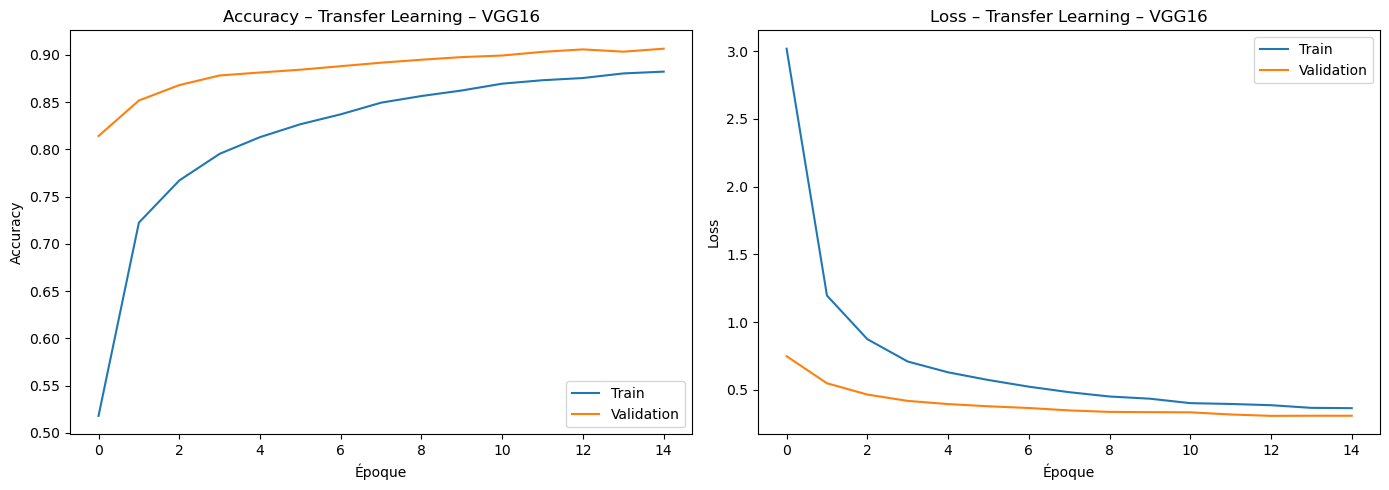

Transfer Learning (VGG16) – Loss test : 0.2549 | Accuracy test : 0.9167


In [38]:
plot_history(history_tl, 'Transfer Learning – VGG16')

loss_tl, acc_tl = model_tl.evaluate(test_gen_tl, verbose=0)
print(f'Transfer Learning (VGG16) – Loss test : {loss_tl:.4f} | Accuracy test : {acc_tl:.4f}')

**Observation :** Le Transfer Learning avec VGG16 converge beaucoup plus rapidement que le CNN entraîné from scratch. Les représentations apprises sur ImageNet sont suffisamment générales pour être utiles sur des images satellitaires.

---
## V. Évaluation et analyse des résultats

In [39]:
# Prédictions du modèle final (Transfer Learning)
test_gen_tl.reset()
y_pred_prob = model_tl.predict(test_gen_tl)
y_pred = np.argmax(y_pred_prob, axis=1)
y_true = test_gen_tl.classes

print(classification_report(y_true, y_pred, target_names=class_names))

85/85 ━━━━━━━━━━━━━━━━━━━━ 19s 221ms/step
                      precision    recall  f1-score   support

          AnnualCrop       0.96      0.94      0.95       300
              Forest       0.94      0.99      0.97       300
HerbaceousVegetation       0.93      0.91      0.92       300
             Highway       0.84      0.79      0.82       250
          Industrial       0.92      0.94      0.93       250
             Pasture       0.88      0.91      0.89       200
       PermanentCrop       0.90      0.86      0.88       250
         Residential       0.91      0.98      0.95       300
               River       0.85      0.85      0.85       250
             SeaLake       1.00      0.95      0.97       300

            accuracy                           0.92      2700
           macro avg       0.91      0.91      0.91      2700
        weighted avg       0.92      0.92      0.92      2700



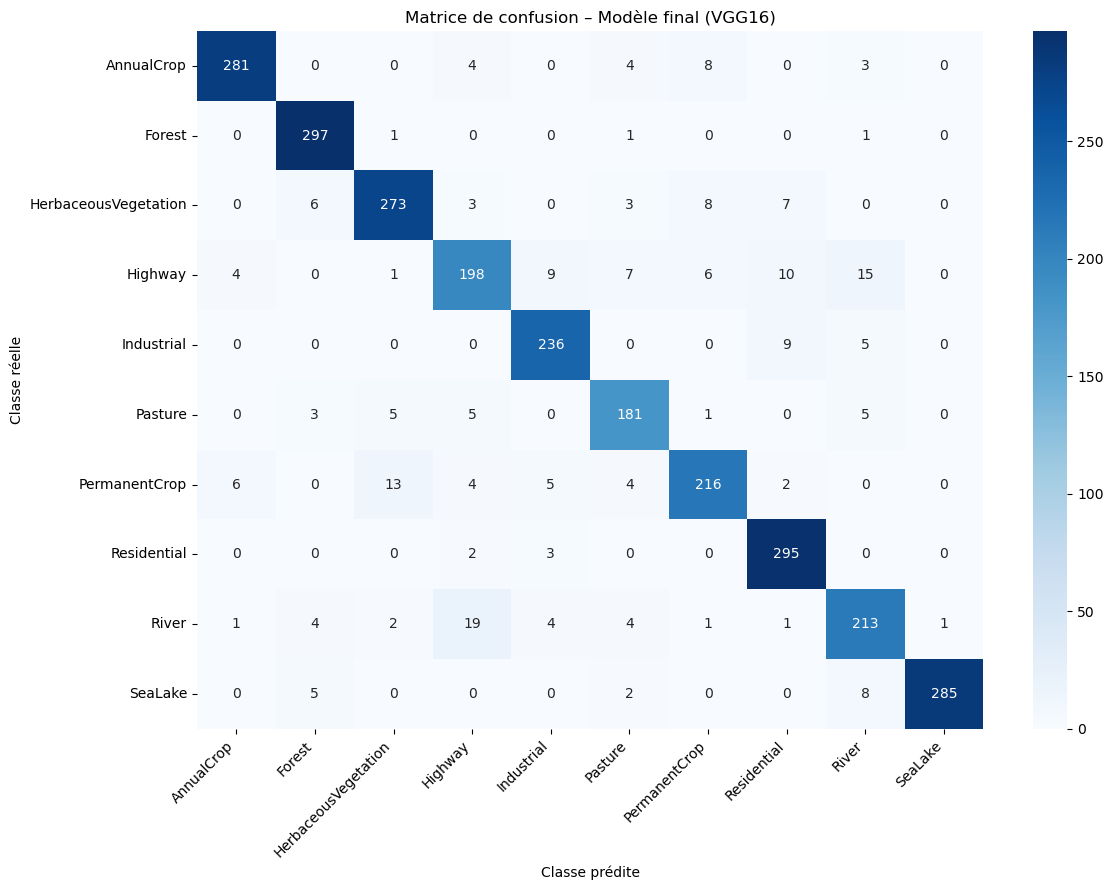

In [40]:
# Matrice de confusion
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(12, 9))
sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues',
    xticklabels=class_names, yticklabels=class_names
)
plt.title('Matrice de confusion – Modèle final (VGG16)')
plt.xlabel('Classe prédite')
plt.ylabel('Classe réelle')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

**Observation :** La matrice de confusion révèle que les classes visuellement proches (`Forest` / `HerbaceousVegetation`, `Residential` / `Industrial`) génèrent le plus de confusions. Les classes avec des signatures visuelles distinctes (`SeaLake`, `River`) sont mieux reconnues.

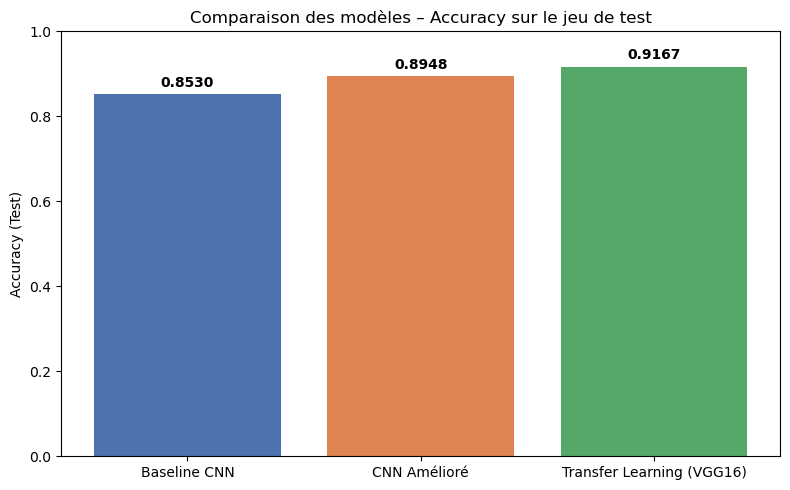

Baseline CNN         : 0.8530
CNN Amélioré         : 0.8948
Transfer Learning    : 0.9167


In [41]:
# Comparaison des trois modèles
modeles = ['Baseline CNN', 'CNN Amélioré', 'Transfer Learning (VGG16)']
accuracies = [acc_b, acc_imp, acc_tl]

plt.figure(figsize=(8, 5))
bars = plt.bar(modeles, accuracies, color=['#4C72B0', '#DD8452', '#55A868'])
plt.ylim(0, 1)
plt.ylabel('Accuracy (Test)')
plt.title('Comparaison des modèles – Accuracy sur le jeu de test')
for bar, acc in zip(bars, accuracies):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
             f'{acc:.4f}', ha='center', va='bottom', fontweight='bold')
plt.tight_layout()
plt.show()

print(f'Baseline CNN         : {acc_b:.4f}')
print(f'CNN Amélioré         : {acc_imp:.4f}')
print(f'Transfer Learning    : {acc_tl:.4f}')

**Résumé des observations :**
- Le **Baseline CNN** fournit une première référence acceptable mais souffre d'overfitting.
- Le **CNN Amélioré** (Dropout + BatchNorm + Augmentation) réduit l'overfitting et améliore la généralisation.
- Le **Transfer Learning VGG16** obtient les meilleures performances grâce aux représentations pré-apprises sur ImageNet.

---
## VI. Discussion et conclusion

### Synthèse des résultats

Ce projet a permis de mettre en place une pipeline complète de classification d'images satellitaires sur le dataset EuroSAT (10 classes, images 64×64).

### Résultats obtenus

| Modèle | Accuracy Test |
|--------|---------------|
| Baseline CNN | 0.8530 |
| CNN Amélioré | 0.8948 |
| Transfer Learning (VGG16) | 0.9167 |

### Limites du modèle

- La résolution de 64×64 pixels limite la capacité du modèle à distinguer les classes visuellement proches.
- VGG16 a été pré-entraîné sur des images naturelles (ImageNet), pas des images satellitaires, ce qui représente un écart de domaine.
- Le fine-tuning des dernières couches de VGG16 pourrait encore améliorer les performances.

### Pistes d'amélioration

- **Fine-tuning** : dégeler les dernières couches de VGG16 et les réentraîner à faible learning rate.
- **ResNet50** : tester une architecture plus profonde avec connexions résiduelles.
- **Augmentation plus agressive** : rotations 90°/180° pertinentes pour les images satellitaires (invariance au point de vue).
- **Modèles spécialisés** : utiliser des modèles pré-entraînés sur des données de télédétection (BigEarthNet).